# Otimização do Random Forest – Passo 6: hiperparâmetros e corte das classes (abordagem B)

**Fixo dos passos anteriores:** abordagem B, candle de 1 min, janela de 12 meses, variáveis da decisão do passo 5.

**Por que a floresta vem por último:** a profundidade e a folha ideais dependem dos dados (cenário) e das variáveis.
Ajustá-las antes seria ajustar para um problema que ainda ia mudar.

**O que testamos:**

| Item | Opções | O que controla |
|---|---|---|
| `max_depth` | 4, 6, 8 | Quantas perguntas em sequência (interações entre variáveis) |
| Folha mínima | 0,5%, 1%, 2% do treino | Quantos minutos, no mínimo, cada probabilidade usa |
| Corte das classes | 3, 5, 10 pts (com profundidade 4 e folha 2%) | O que conta como "sobe" e "desce" |

9 combinações de floresta + 2 cortes extras = **11 modelos**. `max_features = 0,5` e 100 árvores fixos (o passo A2 da
rodada anterior mostrou que 100 árvores estabilizam o resultado).

**Pista do passo 5:** a importância das variáveis é dominada pela volatilidade (`amplitude15`, `volat15`, `volat60`).
Árvores rasas gastam as divisões separando "vai mexer" de "neutro"; árvores mais fundas podem ter espaço para separar
a **direção** dentro de cada regime de volatilidade.

**Critério registrado:** o mesmo dos passos anteriores (candidata com t ≥ 2 e ≥ 3 trimestres; senão, maior t do
ganho bruto).

In [1]:
import os, sys, json, time, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

try:
    import google.colab  # noqa: F401
    PASTA = "/content/data_science_no_mercado_financeiro"
    if not os.path.exists(PASTA):
        subprocess.run(["git", "clone", "https://github.com/anabiaboorges/data_science_no_mercado_financeiro.git", PASTA], check=True)
except ImportError:
    PASTA = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))

sys.path.append(PASTA)
sys.path.append(f"{PASTA}/frentes/ml")
import tt1_comum as t
import otim_rf as o

SAIDA = f"{PASTA}/resultados/ml/otimizacao"
D4 = json.load(open(f"{SAIDA}/decisao_passo4.json", encoding="utf-8"))
D5 = json.load(open(f"{SAIDA}/decisao_passo5.json", encoding="utf-8"))
CANDLE, JANELA, FEATS = D4["candle"], D4["janela_meses"], D5["variaveis"]

MODELOS = {}
for d in [4, 6, 8]:
    for f in [0.005, 0.01, 0.02]:
        MODELOS[f"d{d}_f{f*100:g}_c5"] = (dict(o.RF_PADRAO, max_depth=d, folha_frac=f), 5.0)
for c in [3.0, 10.0]:
    MODELOS[f"d4_f2_c{c:g}"] = (dict(o.RF_PADRAO), c)
json.dump(dict(passo="6 - hiperparâmetros", candle=CANDLE, janela_meses=JANELA, variante=D5["variante"],
               modelos={k: dict(rf=v[0], corte_classe=v[1]) for k, v in MODELOS.items()},
               criterio_candidata=f"esperança > 0, t ≥ {o.T_MIN}, ≥ {o.TRIM_MIN} trimestres positivos",
               criterio_sem_candidatas="maior t do ganho bruto"),
          open(f"{SAIDA}/registro_passo6.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

win = t.carregar(f"{PASTA}/dados/WINN_M1/WIN$N_M1.csv")
wdo = t.carregar(f"{PASTA}/dados/WDON_M1/WDO$N_M1.csv")
df, _ = t.montar_base(win, wdo, CANDLE)
DFX = o.adicionar_features(df)
print(f"{len(DFX):,} candles | {len(FEATS)} variáveis ({D5['variante']}) | {len(MODELOS)} modelos")

686,124 candles | 30 variáveis (base+todas) | 11 modelos


In [2]:
qual, regras = [], []
for nome, (rf, corte) in MODELOS.items():
    t0 = time.time()
    prev, _ = o.walk_forward_b(o.rotular(DFX, corte), FEATS, *t.VALIDACAO, janela_meses=JANELA, rf=rf)
    prev.to_csv(f"{SAIDA}/previsoes/WIN_{CANDLE}_{JANELA}m_rfB_{nome}_val.csv")
    g = o.grade_regras(prev).assign(modelo=nome)
    regras.append(g)
    best = g[g.serie == "modelo"].sort_values("esperanca_pts", ascending=False).iloc[0]
    qual.append(dict(modelo=nome, max_depth=rf["max_depth"], folha_frac=rf["folha_frac"], corte_classe=corte,
                     tempo_s=round(time.time() - t0, 1), **o.qualidade(prev),
                     melhor_regra=best.regra, melhor_limiar_q=best.limiar_q, melhor_esperanca=best.esperanca_pts,
                     melhor_t=best.t_stat, melhor_bruto=best.bruto_pts, melhor_trim_pos=best.trimestres_positivos,
                     n_candidatas=int(g.candidata.sum())))
    q = qual[-1]
    print(f"{nome:>12}: Spearman {q['spearman']:+.4f} | bruto {q['bruto_esperanca_pts']:+.2f} (t {q['bruto_t_stat']:.2f}) | "
          f"melhor {best.regra} q{best.limiar_q:.0%}: {best.esperanca_pts:+.2f} (t {best.t_stat:.2f}) | {q['tempo_s']}s")
qual = pd.DataFrame(qual)
regras = pd.concat(regras, ignore_index=True)
qual.to_csv(f"{SAIDA}/hiperparametros_qualidade_val.csv", index=False)
regras.to_csv(f"{SAIDA}/hiperparametros_regras_val.csv", index=False)
qual.round(4)

  d4_f0.5_c5: Spearman +0.0210 | bruto +0.41 (t 3.68) | melhor por_candle q98%: -3.31 (t -3.98) | 40.2s


    d4_f1_c5: Spearman +0.0199 | bruto +0.40 (t 3.60) | melhor por_candle q95%: -3.35 (t -7.03) | 34.6s


    d4_f2_c5: Spearman +0.0192 | bruto +0.47 (t 4.18) | melhor por_candle q98%: -2.67 (t -3.13) | 37.2s


  d6_f0.5_c5: Spearman +0.0232 | bruto +0.39 (t 3.51) | melhor por_candle q98%: -2.95 (t -3.80) | 104.2s


    d6_f1_c5: Spearman +0.0229 | bruto +0.41 (t 3.69) | melhor por_candle q95%: -3.37 (t -7.26) | 88.4s


    d6_f2_c5: Spearman +0.0205 | bruto +0.42 (t 3.70) | melhor por_candle q98%: -2.84 (t -3.35) | 89.7s


... (2 outputs left out)

    d8_f2_c5: Spearman +0.0200 | bruto +0.37 (t 3.27) | melhor por_candle q98%: -2.76 (t -3.22) | 87.7s


    d4_f2_c3: Spearman +0.0215 | bruto +0.45 (t 4.00) | melhor por_candle q95%: -3.64 (t -7.43) | 70.6s


   d4_f2_c10: Spearman +0.0130 | bruto +0.15 (t 1.29) | melhor segurar q98%: +5.11 (t 0.14) | 85.6s


,modelo,max_depth,folha_frac,corte_classe,tempo_s,spearman,acc_dir,bruto_n_ops,bruto_esperanca_pts,bruto_ep_pts,bruto_t_stat,melhor_regra,melhor_limiar_q,melhor_esperanca,melhor_t,melhor_bruto,melhor_trim_pos,n_candidatas
0,d4_f0.5_c5,4,0.005,5.0,40.2,0.0210,0.5146,141216,0.4120,0.1121,3.6758,por_candle,0.98,-3.3062,-3.9827,1.6938,0,0
1,d4_f1_c5,4,0.010,5.0,34.6,0.0199,0.5135,141216,0.4040,0.1121,3.6044,por_candle,0.95,-3.3458,-7.0251,1.6542,0,0
2,d4_f2_c5,4,0.020,5.0,37.2,0.0192,0.5130,141216,0.4690,0.1121,4.1838,por_candle,0.98,-2.6726,-3.1327,2.3274,1,0
3,d6_f0.5_c5,6,0.005,5.0,104.2,0.0232,0.5144,141216,0.3936,0.1121,3.5115,por_candle,0.98,-2.9487,-3.8002,2.0513,0,0
4,d6_f1_c5,6,0.010,5.0,88.4,0.0229,0.5142,141216,0.4139,0.1121,3.6928,por_candle,0.95,-3.3699,-7.2597,1.6301,0,0
5,d6_f2_c5,6,0.020,5.0,89.7,0.0205,0.5126,141216,0.4151,0.1121,3.7036,por_candle,0.98,-2.8389,-3.3535,2.1611,1,0
6,d8_f0.5_c5,8,0.005,5.0,139.3,0.0243,0.5140,141216,0.4106,0.1121,3.6632,segurar,0.75,-2.6348,-1.5470,2.3652,0,0
7,d8_f1_c5,8,0.010,5.0,87.5,0.0230,0.5134,141216,0.3536,0.1121,3.1546,por_candle,0.95,-3.3515,-6.6966,1.6485,0,0
8,d8_f2_c5,8,0.020,5.0,87.7,0.0200,0.5122,141216,0.3665,0.1121,3.2695,por_candle,0.98,-2.7558,-3.2230,2.2442,1,0
9,d4_f2_c3,4,0.020,3.0,70.6,0.0215,0.5138,141216,0.4486,0.1121,4.0024,por_candle,0.95,-3.6390,-7.4339,1.3610,0,0


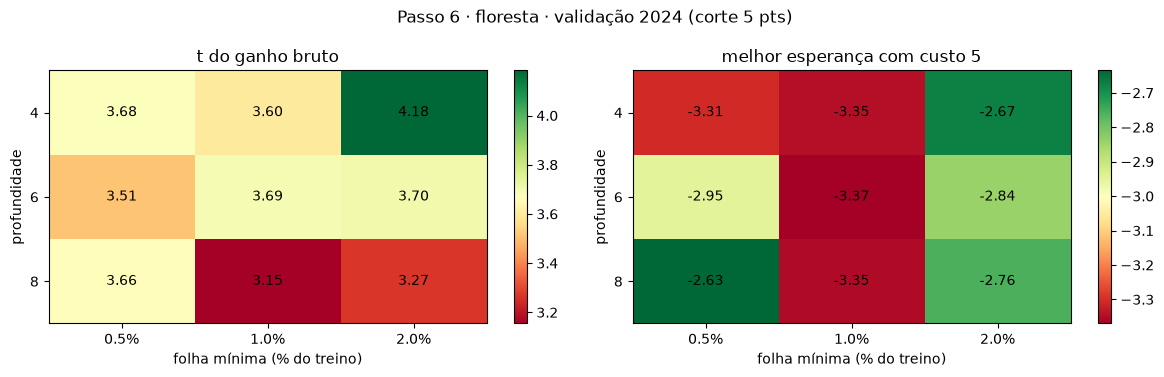

In [3]:
grade = qual[qual.corte_classe == 5.0]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, tit in [(axes[0], "bruto_t_stat", "t do ganho bruto"), (axes[1], "melhor_esperanca", "melhor esperança com custo 5")]:
    piv = grade.pivot(index="max_depth", columns="folha_frac", values=col)
    im = ax.imshow(piv.values, cmap="RdYlGn", aspect="auto")
    ax.set_xticks(range(piv.shape[1]), [f"{c:.1%}" for c in piv.columns]); ax.set_yticks(range(piv.shape[0]), piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center")
    ax.set_xlabel("folha mínima (% do treino)"); ax.set_ylabel("profundidade"); ax.set_title(tit)
    fig.colorbar(im, ax=ax)
fig.suptitle("Passo 6 · floresta · validação 2024 (corte 5 pts)"); fig.tight_layout()
fig.savefig(f"{SAIDA}/hiperparametros_heatmap.png", dpi=150); plt.show()

## Decisão do passo 6

In [4]:
cand = regras[regras.candidata].sort_values("retorno_capital", ascending=False)
if len(cand):
    MOD = cand.iloc[0].modelo
    CRITERIO = "maior retorno sobre capital entre as candidatas"
else:
    MOD = qual.sort_values("bruto_t_stat", ascending=False).iloc[0].modelo
    CRITERIO = "nenhuma candidata: maior t do ganho bruto"
v = qual[qual.modelo == MOD].iloc[0]
rf, corte = MODELOS[MOD]
print("Critério:", CRITERIO)
print(f"Modelo escolhido: {MOD} | Spearman {v.spearman:.4f} | bruto {v.bruto_esperanca_pts:+.2f} (t {v.bruto_t_stat:.2f}) "
      f"| melhor regra {v.melhor_regra} q{v.melhor_limiar_q:.0%}: {v.melhor_esperanca:+.2f} (t {v.melhor_t:.2f})")
print(f"Configurações com esperança > 0: {int(((regras.serie == 'modelo') & (regras.esperanca_pts > 0)).sum())} de "
      f"{int((regras.serie == 'modelo').sum())} | candidatas: {len(cand)}")
json.dump(dict(passo="6 - hiperparâmetros", criterio=CRITERIO, modelo=MOD, rf=rf, corte_classe=corte,
               n_candidatas=int(len(cand)), spearman=float(v.spearman), bruto_pts=float(v.bruto_esperanca_pts),
               bruto_t=float(v.bruto_t_stat)),
          open(f"{SAIDA}/decisao_passo6.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

Critério: nenhuma candidata: maior t do ganho bruto
Modelo escolhido: d4_f2_c5 | Spearman 0.0192 | bruto +0.47 (t 4.18) | melhor regra por_candle q98%: -2.67 (t -3.13)
Configurações com esperança > 0: 1 de 132 | candidatas: 0
